In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/spaceship-titanic/sample_submission.csv
/kaggle/input/competitions/spaceship-titanic/train.csv
/kaggle/input/competitions/spaceship-titanic/test.csv


### Data load

In [2]:
import pandas as pd

train_path = "/kaggle/input/competitions/spaceship-titanic/train.csv"
test_path = "/kaggle/input/competitions/spaceship-titanic/test.csv"

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)


In [3]:
train.shape, test.shape

((8693, 14), (4277, 13))

In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


In [5]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4277 entries, 0 to 4276
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   4277 non-null   object 
 1   HomePlanet    4190 non-null   object 
 2   CryoSleep     4184 non-null   object 
 3   Cabin         4177 non-null   object 
 4   Destination   4185 non-null   object 
 5   Age           4186 non-null   float64
 6   VIP           4184 non-null   object 
 7   RoomService   4195 non-null   float64
 8   FoodCourt     4171 non-null   float64
 9   ShoppingMall  4179 non-null   float64
 10  Spa           4176 non-null   float64
 11  VRDeck        4197 non-null   float64
 12  Name          4183 non-null   object 
dtypes: float64(6), object(7)
memory usage: 434.5+ KB


In [6]:
train.isnull().sum()

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64

In [7]:
test.isnull().sum()

PassengerId       0
HomePlanet       87
CryoSleep        93
Cabin           100
Destination      92
Age              91
VIP              93
RoomService      82
FoodCourt       106
ShoppingMall     98
Spa             101
VRDeck           80
Name             94
dtype: int64

In [8]:
set(train.columns) - set(test.columns)   # {output:'Transported'} 

{'Transported'}

In [9]:
train.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [10]:
test.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name
0,0013_01,Earth,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,0.0,Nelly Carsoning
1,0018_01,Earth,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,0.0,Lerome Peckers
2,0019_01,Europa,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,0.0,Sabih Unhearfus
3,0021_01,Europa,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,585.0,Meratz Caltilter
4,0023_01,Earth,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,0.0,Brence Harperez


In [11]:
train['Transported'].value_counts(normalize=True)

Transported
True     0.503624
False    0.496376
Name: proportion, dtype: float64

In [12]:
train.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [13]:
train.nunique()

PassengerId     8693
HomePlanet         3
CryoSleep          2
Cabin           6560
Destination        3
Age               80
VIP                2
RoomService     1273
FoodCourt       1507
ShoppingMall    1115
Spa             1327
VRDeck          1306
Name            8473
Transported        2
dtype: int64

In [14]:
train.duplicated().sum()

np.int64(0)

In [15]:
train['PassengerId'].str.split('_').str[0].nunique()

6217

### EDA

In [16]:
#Target vs categorical feature

tr = train.copy() #raw train, missing fill er agey

for c in ['HomePlanet', 'CryoSleep', 'Destination', 'VIP']:
    print(tr.groupby(c)['Transported'].mean(), '\n')

HomePlanet
Earth     0.423946
Europa    0.658846
Mars      0.523024
Name: Transported, dtype: float64 

CryoSleep
False    0.328921
True     0.817583
Name: Transported, dtype: float64 

Destination
55 Cancri e      0.610000
PSO J318.5-22    0.503769
TRAPPIST-1e      0.471175
Name: Transported, dtype: float64 

VIP
False    0.506332
True     0.381910
Name: Transported, dtype: float64 



In [17]:
#Spending vs target

spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
tr['TotalSpend'] = tr[spend_cols].sum(axis=1)
tr.groupby(tr['TotalSpend'] == 0)['Transported'].mean()

TotalSpend
False    0.298611
True     0.786477
Name: Transported, dtype: float64

In [18]:
#CryoSleep rule check

tr[tr['CryoSleep'] == True][spend_cols].sum().sum()

np.float64(0.0)

/tmp/ipykernel_16/4107145967.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tr.groupby(pd.cut(tr['Age'], bins=[0,12,18,30,50,80]))['Transported'].mean().plot(kind='bar')


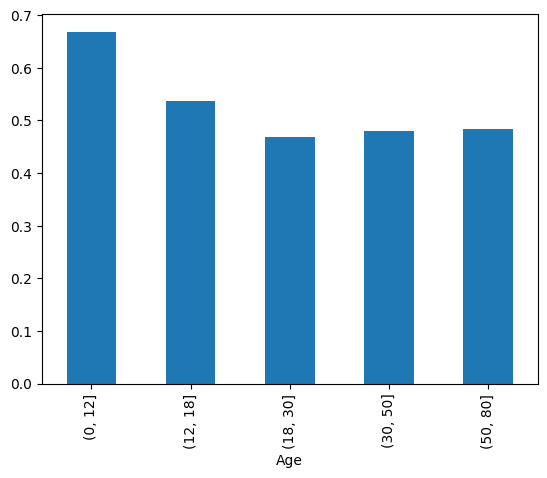

In [19]:
#Age vs target

import matplotlib.pyplot as plt
tr.groupby(pd.cut(tr['Age'], bins=[0,12,18,30,50,80]))['Transported'].mean().plot(kind='bar')
plt.show()

In [20]:
#Group ar Cabin-based EDA

tr['Group'] = tr['PassengerId'].str.split('_').str[0]
tr['GroupSize'] = tr.groupby('Group')['PassengerId'].transform('count')
tr.groupby('GroupSize')['Transported'].mean()

tr[['Deck','CabinNum','Side']] = tr['Cabin'].str.split('/', expand=True)
tr.groupby('Deck')['Transported'].mean()
tr.groupby('Side')['Transported'].mean()

Side
P    0.451260
S    0.555037
Name: Transported, dtype: float64

In [21]:
#Je output gulo miss hoyeche oigulo dekhi (GroupSize, Deck):

print(tr.groupby('GroupSize')['Transported'].mean(), '\n')
print(tr.groupby('Deck')['Transported'].mean())

GroupSize
1    0.452445
2    0.538050
3    0.593137
4    0.640777
5    0.592453
6    0.614943
7    0.541126
8    0.394231
Name: Transported, dtype: float64 

Deck
A    0.496094
B    0.734275
C    0.680054
D    0.433054
E    0.357306
F    0.439871
G    0.516217
T    0.200000
Name: Transported, dtype: float64


In [22]:
#Kichu extra check (spending alada alada):

for c in spend_cols:
    print(c, tr[tr[c] > 0]['Transported'].mean(), tr[tr[c] == 0]['Transported'].mean())

RoomService 0.2599659284497445 0.6333154025461718
FoodCourt 0.34544859201047806 0.5909090909090909
ShoppingMall 0.3171152518978606 0.5987112940755325
Spa 0.27746390458254866 0.6391810668670173
VRDeck 0.27541528239202656 0.6280254777070063


In [23]:
#Train and Test combined

train['is_train'] = 1
test['is_train'] = 0
df = pd.concat([train, test], ignore_index=True)
df.shape

(12970, 15)

In [24]:
spend_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
print(spend_cols)

['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']


### Feature engineering

In [25]:
df['Group'] = df['PassengerId'].str.split('_').str[0]
df['GroupSize'] = df.groupby('Group')['PassengerId'].transform('count')
df['IsSolo'] = (df['GroupSize'] == 1).astype(int)

df[['Deck', 'CabinNum', 'Side']] = df['Cabin'].str.split('/', expand=True)
df['CabinNum'] = pd.to_numeric(df['CabinNum'])

### Missing fill

In [26]:
# 1. CryoSleep True hole spending = 0 (EDA te verified)
cryo = df['CryoSleep'] == True
for c in spend_cols:
    df.loc[cryo & df[c].isna(), c] = 0

# 2. Spending > 0 hole CryoSleep = False
df['TotalSpend'] = df[spend_cols].sum(axis=1)
df.loc[df['CryoSleep'].isna() & (df['TotalSpend'] > 0), 'CryoSleep'] = False

# 3. Group theke fill
for c in ['HomePlanet', 'Deck', 'Side', 'Destination']:
    grp_mode = df.groupby('Group')[c].transform(
        lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
    df[c] = df[c].fillna(grp_mode)

# 4. Baki missing: mode / median
for c in ['HomePlanet', 'Deck', 'Side', 'Destination', 'CryoSleep', 'VIP']:
    df[c] = df[c].fillna(df[c].mode()[0])

df['Age'] = df['Age'].fillna(df['Age'].median())
df['CabinNum'] = df['CabinNum'].fillna(df['CabinNum'].median())
for c in spend_cols:
    df[c] = df[c].fillna(0)

/tmp/ipykernel_16/2962288789.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[c] = df[c].fillna(df[c].mode()[0])


In [27]:
# Final features 
df['TotalSpend'] = df[spend_cols].sum(axis=1)
df['NoSpend'] = (df['TotalSpend'] == 0).astype(int)
df['IsChild'] = (df['Age'] <= 12).astype(int)

print(df.isnull().sum())

PassengerId        0
HomePlanet         0
CryoSleep          0
Cabin            299
Destination        0
Age                0
VIP                0
RoomService        0
FoodCourt          0
ShoppingMall       0
Spa                0
VRDeck             0
Name             294
Transported     4277
is_train           0
Group              0
GroupSize          0
IsSolo             0
Deck               0
CabinNum           0
Side               0
TotalSpend         0
NoSpend            0
IsChild            0
dtype: int64


### Encoding + Baseline model + GroupKFold CV

In [28]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import accuracy_score
import lightgbm as lgb

# 1. Boolean column gulo ke 0/1 e convert
for c in ['CryoSleep', 'VIP']:
    df[c] = df[c].astype(bool).astype(int)

# 2. Categorical ke one-hot encoding
cat_cols = ['HomePlanet', 'Destination', 'Deck', 'Side']
df_enc = pd.get_dummies(df, columns=cat_cols, drop_first=False)

# 3. Drop unnecessary column
drop_cols = ['PassengerId', 'Cabin', 'Name', 'Group', 'is_train', 'Transported']

# 4. Train / test alada kora
train_df = df_enc[df_enc['is_train'] == 1].copy()
test_df = df_enc[df_enc['is_train'] == 0].copy()

X = train_df.drop(columns=drop_cols)
y = train_df['Transported'].astype(int)
groups = train_df['Group']
X_test = test_df.drop(columns=drop_cols)

print(X.shape, X_test.shape)   # column shonkha same hote hobe

(8693, 30) (4277, 30)


In [29]:
# 5. GroupKFold CV with LightGBM (baseline)
gkf = GroupKFold(n_splits=5)
scores = []

for fold, (tr_idx, val_idx) in enumerate(gkf.split(X, y, groups)):
    model = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, random_state=42, verbose=-1)
    model.fit(X.iloc[tr_idx], y.iloc[tr_idx])
    pred = model.predict(X.iloc[val_idx])
    acc = accuracy_score(y.iloc[val_idx], pred)
    scores.append(acc)
    print(f'Fold {fold+1}: {acc:.4f}')

print('Mean CV accuracy:', np.mean(scores))

Fold 1: 0.7959
Fold 2: 0.8005
Fold 3: 0.8212
Fold 4: 0.8234
Fold 5: 0.8182
Mean CV accuracy: 0.8118046626799658


In [30]:
def cv_score(X, y, groups, model_fn):
    gkf = GroupKFold(n_splits=5)
    scores = []
    for tr_idx, val_idx in gkf.split(X, y, groups):
        m = model_fn()
        m.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        scores.append(accuracy_score(y.iloc[val_idx], m.predict(X.iloc[val_idx])))
    return np.mean(scores)

lgbm = lambda: lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03,
                                  num_leaves=15, random_state=42, verbose=-1)

print('Baseline LGBM:', cv_score(X, y, groups, lgbm))   

Baseline LGBM: 0.8118046626799658


### Feature importance + submission

In [31]:
# 1. Feature importance
model = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03,
                           num_leaves=15, random_state=42, verbose=-1)
#Full train data diye train
model.fit(X, y)

imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(15))

#Test e predict
preds = model.predict(X_test).astype(bool)

# 2. Submission file

sub = pd.DataFrame({'PassengerId': test_df['PassengerId'], 'Transported': preds})
sub.to_csv('submission.csv', index=False)

print(sub.head())
print(sub['Transported'].value_counts(normalize=True))

CabinNum            585
Spa                 475
VRDeck              473
TotalSpend          371
FoodCourt           366
RoomService         307
Age                 306
ShoppingMall        243
Side_P              157
Deck_E              127
HomePlanet_Earth    111
Deck_C              108
CryoSleep            91
Deck_F               72
GroupSize            61
dtype: int32
     PassengerId  Transported
8693     0013_01         True
8694     0018_01        False
8695     0019_01         True
8696     0021_01         True
8697     0023_01         True
Transported
True     0.528174
False    0.471826
Name: proportion, dtype: float64
